In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/neerajmehla28/chats-data/conversations_fixed.csv


# Northstar Router — Fine-Tuning
### Neeraj — MMAI 894

**Task:** replace the prompted router with a fine-tuned small model. Given a customer's chat
message (`customer_text`), predict:
- `request_type` — which of 10 categories this is
- `needs_escalation` — does a human need to take over

**Base model:** `distilbert-base-multilingual-cased` (handles English + French), fine-tuned with
two output heads on top of one shared encoder — one head for the 10-way type, one for the
escalation yes/no.

**Data:** `conversations_fixed.csv` — 130 train / 30 validation / 40 test. Train and validate
here; the 40 test rows are touched only once, at the very end, to compare against the small- and
large-prompted baselines.

In [3]:
!pip install -q transformers datasets scikit-learn

In [4]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Step 2 — Load the data

Use `conversations_fixed.csv` (the version with the billing-escalation fix applied). Attach it
to this Kaggle notebook the same way as before: Add Data → Upload → re-run the path-finder below
to get its real path.

In [5]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/neerajmehla28/chats-data/conversations_fixed.csv


In [6]:
DATA_PATH = "/kaggle/input/datasets/neerajmehla28/chats-data/conversations_fixed.csv"

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

print("Shape:", df.shape)
print(df["split"].value_counts())
print()
print(df["request_type"].value_counts())

Shape: (200, 27)
split
train         130
test           40
validation     30
Name: count, dtype: int64

request_type
recall_inquiry         20
out_of_scope           20
warranty_claim         20
roadside_assistance    20
needs_human            20
parts_order            20
repair_status          20
billing_dispute        20
book_service           20
lease_end_return       20
Name: count, dtype: int64


## Step 3 — Encode labels

Models predict numbers, not strings so `request_type` needs a fixed string→number mapping.
We use the same order as the project's `RequestType` enum in `contracts.py`, so our label ids
stay consistent with the rest of the codebase. `needs_escalation` is already boolean, so it
just becomes 0/1.

In [7]:
REQUEST_TYPES = [
    "book_service", "repair_status", "warranty_claim", "recall_inquiry",
    "roadside_assistance", "parts_order", "billing_dispute", "lease_end_return",
    "out_of_scope", "needs_human",
]
label2id = {label: i for i, label in enumerate(REQUEST_TYPES)}
id2label = {i: label for label, i in label2id.items()}

df["type_label"] = df["request_type"].map(label2id)
df["escalation_label"] = df["needs_escalation"].astype(int)

assert df["type_label"].isna().sum() == 0, "Found a request_type not in REQUEST_TYPES!"

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df   = df[df["split"] == "validation"].reset_index(drop=True)
test_df  = df[df["split"] == "test"].reset_index(drop=True)

print("Train:", len(train_df), " Validation:", len(val_df), " Test:", len(test_df))
train_df[["request_type", "type_label", "needs_escalation", "escalation_label"]].head()

Train: 130  Validation: 30  Test: 40


,request_type,type_label,needs_escalation,escalation_label
0,warranty_claim,2,False,0
1,roadside_assistance,4,True,1
2,out_of_scope,8,True,1
3,parts_order,5,False,0
4,repair_status,1,True,1


## Step 4 — Tokenize the text

The tokenizer turns each `customer_text` into: a list of numeric token IDs (`input_ids`) and an
`attention_mask` (which positions are real text vs. padding). We first load the tokenizer that
matches our base model exactly, then check how long the messages actually are, so we pick a
sensible fixed length to pad/truncate to — too short cuts off real content, too long wastes GPU
memory and training time for no benefit.

In [8]:
MODEL_NAME = "distilbert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Quick sanity check: tokenize one example and look at what comes out.
sample_text = train_df["customer_text"].iloc[0]
sample_tokens = tokenizer(sample_text)

print("Original text:", sample_text[:120], "...")
print()
print("Token IDs (first 20):", sample_tokens["input_ids"][:20])
print("Attention mask (first 20):", sample_tokens["attention_mask"][:20])
print()
print("Decoded back:", tokenizer.decode(sample_tokens["input_ids"][:20]))

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Original text: Hi, I'm handling this for my mother, Jessica Kane, who's 82. The power liftgate on her 2021 Meridian Halden stopped work ...

Token IDs (first 20): [101, 20065, 117, 146, 112, 181, 52703, 10531, 10142, 15127, 15293, 117, 25675, 21765, 117, 10479, 112, 187, 12180, 119]
Attention mask (first 20): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Decoded back: [CLS] Hi, I ' m handling this for my mother, Jessica Kane, who ' s 82.


count    200.000000
mean     142.335000
std       37.409224
min       17.000000
25%      126.000000
50%      145.000000
75%      166.000000
max      227.000000
Name: customer_text, dtype: float64


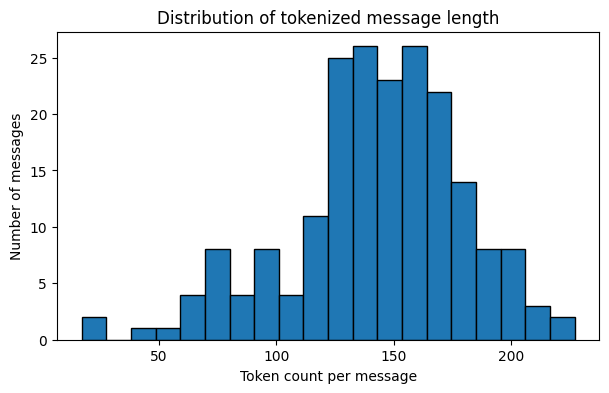

In [9]:
all_texts = pd.concat([train_df["customer_text"], val_df["customer_text"], test_df["customer_text"]])
token_lengths = all_texts.apply(lambda t: len(tokenizer(t)["input_ids"]))

print(token_lengths.describe())
plt.figure(figsize=(7, 4))
plt.hist(token_lengths, bins=20, edgecolor="black")
plt.xlabel("Token count per message")
plt.ylabel("Number of messages")
plt.title("Distribution of tokenized message length")
plt.show()

## Step 5 — Build the tokenized tensors

With `max_length=256` chosen, tokenize each split. `padding="max_length"` pads every message up
to 256 tokens (so every example in a batch is the same size), `truncation=True` is a safety net
in case any message ever exceeds 256 (none do here, confirmed above). The result for each split
is a dictionary of `input_ids` and `attention_mask` tensors, ready to feed into the model.

In [10]:
MAX_LENGTH = 256

def tokenize_split(texts):
    return tokenizer(
        list(texts),
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )

train_enc = tokenize_split(train_df["customer_text"])
val_enc   = tokenize_split(val_df["customer_text"])
test_enc  = tokenize_split(test_df["customer_text"])

print("Train input_ids shape:", train_enc["input_ids"].shape)
print("Validation input_ids shape:", val_enc["input_ids"].shape)
print("Test input_ids shape:", test_enc["input_ids"].shape)

Train input_ids shape: torch.Size([130, 256])
Validation input_ids shape: torch.Size([30, 256])
Test input_ids shape: torch.Size([40, 256])


## Step 6 — Build the two-head model

One shared DistilBERT reads the tokenized message. We take the hidden state at the `[CLS]`
position (the first token) as a summary vector for the whole message — this is the standard way
encoder models are used for classification. That summary vector then feeds into two separate,
small linear layers ("heads"):

- **Type head:** outputs 10 numbers (one score per request type)
- **Escalation head:** outputs 1 number (a score for "needs escalation")

A dropout layer sits before the heads — during training, it randomly zeroes out some of the
summary vector's values each pass, which forces the heads to not over-rely on any single piece
of the representation. This is a standard way to reduce overfitting, which matters here because
we only have 130 training examples.

In [11]:
class RouterClassifier(nn.Module):
    def __init__(self, model_name, num_types, dropout=0.2):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden_size = self.encoder.config.hidden_size  # 768 for DistilBERT

        self.dropout = nn.Dropout(dropout)
        self.type_head = nn.Linear(hidden_size, num_types)       # 10-way
        self.escalation_head = nn.Linear(hidden_size, 1)         # binary

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls_vector = outputs.last_hidden_state[:, 0, :]  # [CLS] token's representation
        cls_vector = self.dropout(cls_vector)

        type_logits = self.type_head(cls_vector)
        escalation_logits = self.escalation_head(cls_vector).squeeze(-1)
        return type_logits, escalation_logits

model = RouterClassifier(MODEL_NAME, num_types=len(REQUEST_TYPES)).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model loaded on {device}. Total parameters: {n_params:,}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  542MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded on cuda. Total parameters: 134,742,539


## Step 7 — Training setup

Before writing the training loop, three things need to be defined:

- **Batching:** group examples into small batches (here, 16 at a time) instead of feeding all
  130 at once — this is standard for GPU memory efficiency and also helps the model generalize
  rather than memorize exact examples.
- **Loss functions:** since we have two different predictions, we need two different loss
  functions, added together into one combined loss the model optimizes:
  - `CrossEntropyLoss` for the 10-way type (standard for "pick one out of several categories")
  - `BCEWithLogitsLoss` for escalation (standard for "yes or no")
- **Optimizer:** `AdamW`, the standard choice for fine-tuning transformer models, with a small
  learning rate (`2e-5`) — small because we're *adjusting* an already-trained model, not training
  from scratch; a big learning rate would wreck its existing language understanding.

These three choices (batch size, learning rate, epochs) are exactly the hyperparameters the
report needs recorded — noted here, logged again at the end.

In [12]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 16
LEARNING_RATE = 2e-5
EPOCHS = 10  # starting point; we'll watch validation loss and can stop earlier

train_labels_type = torch.tensor(train_df["type_label"].values, dtype=torch.long)
train_labels_esc  = torch.tensor(train_df["escalation_label"].values, dtype=torch.float)
val_labels_type   = torch.tensor(val_df["type_label"].values, dtype=torch.long)
val_labels_esc    = torch.tensor(val_df["escalation_label"].values, dtype=torch.float)

train_dataset = TensorDataset(train_enc["input_ids"], train_enc["attention_mask"], train_labels_type, train_labels_esc)
val_dataset   = TensorDataset(val_enc["input_ids"], val_enc["attention_mask"], val_labels_type, val_labels_esc)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

type_loss_fn = nn.CrossEntropyLoss()
escalation_loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

print(f"Batches per epoch (train): {len(train_loader)}")
print(f"Batches per epoch (val): {len(val_loader)}")
print(f"Hyperparameters — batch_size={BATCH_SIZE}, lr={LEARNING_RATE}, epochs={EPOCHS}")

Batches per epoch (train): 9
Batches per epoch (val): 2
Hyperparameters — batch_size=16, lr=2e-05, epochs=10


## Step 8 — Training loop

For each epoch: run every training batch through the model, compute the combined loss, and
update the model's weights (`loss.backward()` + `optimizer.step()`). Then — without updating
weights — check performance on the validation set. This "train, then validate" pattern each
epoch is how we catch overfitting early: if training loss keeps dropping but validation loss
starts rising, the model is memorizing the 130 training examples rather than learning the task.

We save a copy of the model's weights whenever it achieves the best validation loss so far, so
we end up with the best-performing version, not just whatever epoch happens to finish last.

In [13]:
def run_epoch(loader, training: bool):
    model.train() if training else model.eval()
    total_loss, total_type_correct, total_esc_correct, n = 0.0, 0, 0, 0

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for input_ids, attention_mask, type_labels, esc_labels in loader:
            input_ids, attention_mask = input_ids.to(device), attention_mask.to(device)
            type_labels, esc_labels = type_labels.to(device), esc_labels.to(device)

            type_logits, esc_logits = model(input_ids, attention_mask)
            loss = type_loss_fn(type_logits, type_labels) + escalation_loss_fn(esc_logits, esc_labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            batch_n = input_ids.size(0)
            total_loss += loss.item() * batch_n
            total_type_correct += (type_logits.argmax(dim=1) == type_labels).sum().item()
            total_esc_correct += ((esc_logits > 0).float() == esc_labels).sum().item()
            n += batch_n

    return total_loss / n, total_type_correct / n, total_esc_correct / n


history = []
best_val_loss = float("inf")
best_state = None

for epoch in range(1, EPOCHS + 1):
    train_loss, train_type_acc, train_esc_acc = run_epoch(train_loader, training=True)
    val_loss, val_type_acc, val_esc_acc = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
        "train_type_acc": train_type_acc, "val_type_acc": val_type_acc,
        "train_esc_acc": train_esc_acc, "val_esc_acc": val_esc_acc,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

    print(f"Epoch {epoch:2d} | train_loss={train_loss:.3f} val_loss={val_loss:.3f} "
          f"| val_type_acc={val_type_acc:.2f} val_esc_acc={val_esc_acc:.2f}")

model.load_state_dict(best_state)
print("\nLoaded best model (lowest validation loss).")

Epoch  1 | train_loss=3.025 val_loss=3.068 | val_type_acc=0.07 val_esc_acc=0.47
Epoch  2 | train_loss=2.922 val_loss=3.068 | val_type_acc=0.07 val_esc_acc=0.47
Epoch  3 | train_loss=2.859 val_loss=3.091 | val_type_acc=0.10 val_esc_acc=0.43
Epoch  4 | train_loss=2.783 val_loss=3.113 | val_type_acc=0.10 val_esc_acc=0.50
Epoch  5 | train_loss=2.680 val_loss=3.138 | val_type_acc=0.10 val_esc_acc=0.57
Epoch  6 | train_loss=2.512 val_loss=3.115 | val_type_acc=0.17 val_esc_acc=0.63
Epoch  7 | train_loss=2.297 val_loss=3.099 | val_type_acc=0.17 val_esc_acc=0.53
Epoch  8 | train_loss=2.055 val_loss=3.041 | val_type_acc=0.17 val_esc_acc=0.67
Epoch  9 | train_loss=1.799 val_loss=3.006 | val_type_acc=0.17 val_esc_acc=0.73
Epoch 10 | train_loss=1.557 val_loss=2.945 | val_type_acc=0.20 val_esc_acc=0.83

Loaded best model (lowest validation loss).


## Step 8b — Retrain with more epochs

Resetting the model to fresh pretrained weights (undoing the first, under-trained run) and
retraining with `EPOCHS=30` instead of 10. Everything else — loss functions, optimizer settings,
batching — stays the same, so this is a clean, single-variable change: more training time, same
setup. `history` is also reset so our final training curve reflects just this run, not a mix of
both attempts.

In [14]:
EPOCHS = 30

# Fresh model + optimizer, so this run starts from the same pretrained starting point as before.
model = RouterClassifier(MODEL_NAME, num_types=len(REQUEST_TYPES)).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

history = []
best_val_loss = float("inf")
best_state = None

for epoch in range(1, EPOCHS + 1):
    train_loss, train_type_acc, train_esc_acc = run_epoch(train_loader, training=True)
    val_loss, val_type_acc, val_esc_acc = run_epoch(val_loader, training=False)

    history.append({
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
        "train_type_acc": train_type_acc, "val_type_acc": val_type_acc,
        "train_esc_acc": train_esc_acc, "val_esc_acc": val_esc_acc,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

    print(f"Epoch {epoch:2d} | train_loss={train_loss:.3f} val_loss={val_loss:.3f} "
          f"| val_type_acc={val_type_acc:.2f} val_esc_acc={val_esc_acc:.2f}")

model.load_state_dict(best_state)
print("\nLoaded best model (lowest validation loss).")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Epoch  1 | train_loss=3.024 val_loss=3.045 | val_type_acc=0.00 val_esc_acc=0.47
Epoch  2 | train_loss=2.946 val_loss=3.052 | val_type_acc=0.03 val_esc_acc=0.50
Epoch  3 | train_loss=2.871 val_loss=3.053 | val_type_acc=0.03 val_esc_acc=0.50
Epoch  4 | train_loss=2.778 val_loss=3.056 | val_type_acc=0.07 val_esc_acc=0.50
Epoch  5 | train_loss=2.653 val_loss=3.041 | val_type_acc=0.03 val_esc_acc=0.67
Epoch  6 | train_loss=2.451 val_loss=3.045 | val_type_acc=0.03 val_esc_acc=0.70
Epoch  7 | train_loss=2.224 val_loss=3.020 | val_type_acc=0.10 val_esc_acc=0.73
Epoch  8 | train_loss=1.934 val_loss=2.955 | val_type_acc=0.10 val_esc_acc=0.73
Epoch  9 | train_loss=1.650 val_loss=2.818 | val_type_acc=0.23 val_esc_acc=0.73
Epoch 10 | train_loss=1.330 val_loss=2.748 | val_type_acc=0.23 val_esc_acc=0.77
Epoch 11 | train_loss=1.059 val_loss=2.746 | val_type_acc=0.20 val_esc_acc=0.77
Epoch 12 | train_loss=0.836 val_loss=2.669 | val_type_acc=0.30 val_esc_acc=0.77
Epoch 13 | train_loss=0.619 val_loss=2.6

## Step 9 — Visualize the training curves

Plotting train vs. validation loss (and accuracy) side by side makes the overfitting point
visually obvious — the moment the two lines start diverging — which is exactly where our
checkpoint was taken. This plot goes directly into the report appendix as the "learning curve."

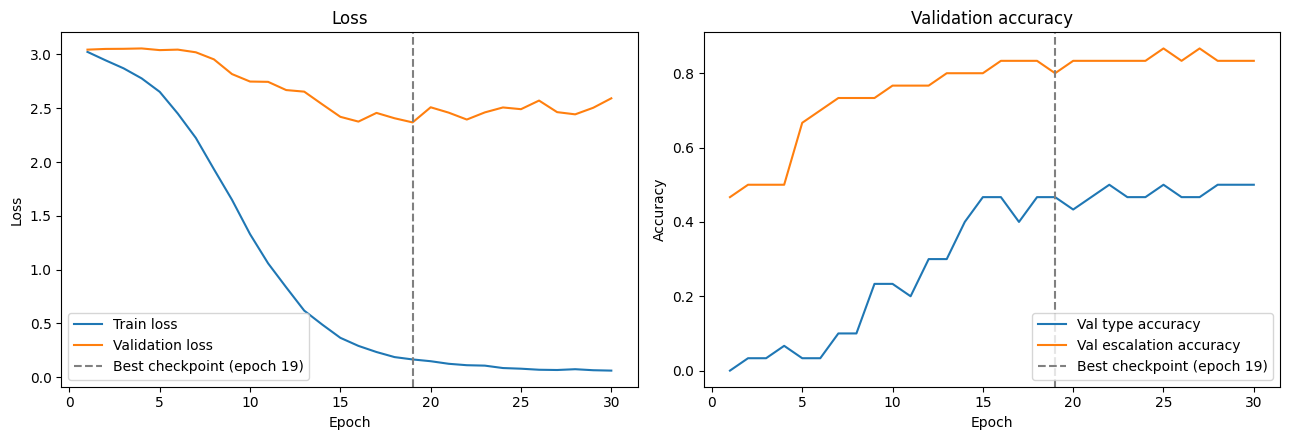

Best epoch: 19
    epoch  train_loss  val_loss  train_type_acc  val_type_acc  train_esc_acc  \
18     19    0.165372  2.368632             1.0      0.466667            1.0   

    val_esc_acc  
18          0.8  


In [15]:
hist_df = pd.DataFrame(history)
best_epoch = hist_df.loc[hist_df["val_loss"].idxmin(), "epoch"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(hist_df["epoch"], hist_df["train_loss"], label="Train loss")
axes[0].plot(hist_df["epoch"], hist_df["val_loss"], label="Validation loss")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label=f"Best checkpoint (epoch {best_epoch})")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(hist_df["epoch"], hist_df["val_type_acc"], label="Val type accuracy")
axes[1].plot(hist_df["epoch"], hist_df["val_esc_acc"], label="Val escalation accuracy")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best checkpoint (epoch {best_epoch})")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].set_title("Validation accuracy"); axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

print(f"Best epoch: {best_epoch}")
print(hist_df.loc[hist_df['epoch'] == best_epoch])

## Step 10 — Detailed validation metrics

Overall accuracy hides *which* classes the model struggles with. A confusion matrix shows this
directly: rows = true label, columns = predicted label, so anything off the diagonal is a
mistake, and the pattern of mistakes (e.g. always confusing two specific types) is informative,
not just the error count. Macro F1 averages performance equally across all 10 classes (rather
than being dominated by whichever class the model happens to be best at) — this is the metric
named in the brief for the three-model comparison table.

Macro F1 (request type): 0.445

Per-class accuracy:
  book_service           n= 2  acc=0.50
  repair_status          n= 2  acc=0.50
  warranty_claim         n= 4  acc=0.50
  recall_inquiry         n= 3  acc=0.33
  roadside_assistance    n= 3  acc=0.67
  parts_order            n= 3  acc=0.00
  billing_dispute        n= 4  acc=0.75
  lease_end_return       n= 3  acc=0.67
  out_of_scope           n= 3  acc=0.00
  needs_human            n= 3  acc=0.67


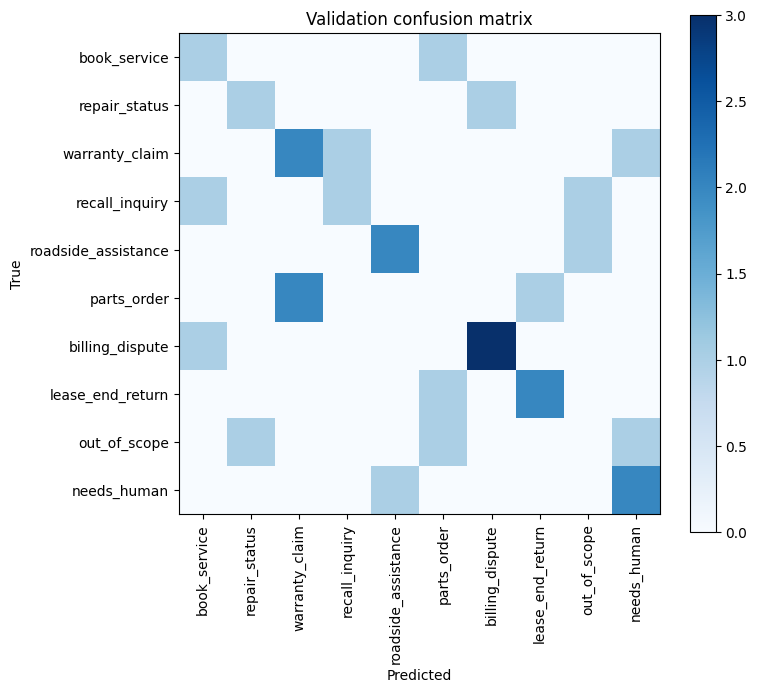

In [16]:
model.eval()
with torch.no_grad():
    input_ids = val_enc["input_ids"].to(device)
    attention_mask = val_enc["attention_mask"].to(device)
    type_logits, esc_logits = model(input_ids, attention_mask)
    val_type_preds = type_logits.argmax(dim=1).cpu().numpy()
    val_esc_preds = (esc_logits > 0).long().cpu().numpy()

val_type_true = val_df["type_label"].values
val_esc_true = val_df["escalation_label"].values

macro_f1 = f1_score(val_type_true, val_type_preds, average="macro")
print(f"Macro F1 (request type): {macro_f1:.3f}")
print()
print("Per-class accuracy:")
for i, name in id2label.items():
    mask = val_type_true == i
    if mask.sum() > 0:
        acc = (val_type_preds[mask] == val_type_true[mask]).mean()
        print(f"  {name:22s} n={mask.sum():2d}  acc={acc:.2f}")

cm = confusion_matrix(val_type_true, val_type_preds, labels=list(id2label.keys()))
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), [id2label[i] for i in range(10)], rotation=90)
plt.yticks(range(10), [id2label[i] for i in range(10)])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Validation confusion matrix")
plt.colorbar()
plt.tight_layout()
plt.savefig("confusion_matrix_val.png", dpi=150)
plt.show()

## Step 11 — Evaluate on the 40 held-out test chats (the real comparison)

This is the only time the test set gets used. We run the best checkpoint (epoch 19) on all 40
test rows and compute the same metrics as validation — type accuracy, macro F1, per-class
accuracy, escalation accuracy/precision/recall — plus **latency**: how long one prediction takes.
Latency is measured one message at a time (not batched), since that's how the real router
actually gets used — one chat at a time, not 40 at once.

In [17]:
import time
from sklearn.metrics import precision_score, recall_score

model.eval()

# Batch predictions for accuracy metrics
with torch.no_grad():
    input_ids = test_enc["input_ids"].to(device)
    attention_mask = test_enc["attention_mask"].to(device)
    type_logits, esc_logits = model(input_ids, attention_mask)
    test_type_preds = type_logits.argmax(dim=1).cpu().numpy()
    test_esc_preds = (esc_logits > 0).long().cpu().numpy()

test_type_true = test_df["type_label"].values
test_esc_true = test_df["escalation_label"].values

test_type_acc = accuracy_score(test_type_true, test_type_preds)
test_macro_f1 = f1_score(test_type_true, test_type_preds, average="macro")
test_esc_acc = accuracy_score(test_esc_true, test_esc_preds)
test_esc_recall = recall_score(test_esc_true, test_esc_preds)
test_esc_precision = precision_score(test_esc_true, test_esc_preds)

# One-at-a-time latency (realistic: how the router is actually called)
latencies_ms = []
with torch.no_grad():
    for i in range(len(test_df)):
        single_ids = test_enc["input_ids"][i:i+1].to(device)
        single_mask = test_enc["attention_mask"][i:i+1].to(device)
        start = time.perf_counter()
        _ = model(single_ids, single_mask)
        torch.cuda.synchronize() if device.type == "cuda" else None
        latencies_ms.append((time.perf_counter() - start) * 1000)

print("=== Fine-tuned DistilBERT — TEST SET RESULTS ===")
print(f"Type accuracy:        {test_type_acc:.3f}")
print(f"Macro F1 (type):      {test_macro_f1:.3f}")
print(f"Escalation accuracy:  {test_esc_acc:.3f}")
print(f"Escalation recall:    {test_esc_recall:.3f}")
print(f"Escalation precision: {test_esc_precision:.3f}")
print(f"Latency (mean, ms):   {np.mean(latencies_ms):.1f}")
print(f"Latency (p95, ms):    {np.percentile(latencies_ms, 95):.1f}")

=== Fine-tuned DistilBERT — TEST SET RESULTS ===
Type accuracy:        0.450
Macro F1 (type):      0.446
Escalation accuracy:  0.825
Escalation recall:    0.789
Escalation precision: 0.833
Latency (mean, ms):   9.1
Latency (p95, ms):    9.7


## Step 12 — Test set confusion matrix + save results

Same confusion matrix as before, now on the actual test set. Results are also saved to a CSV —
this becomes one row of the final three-model comparison table once baselines (2) and (3) are
run on the same 40 chats.

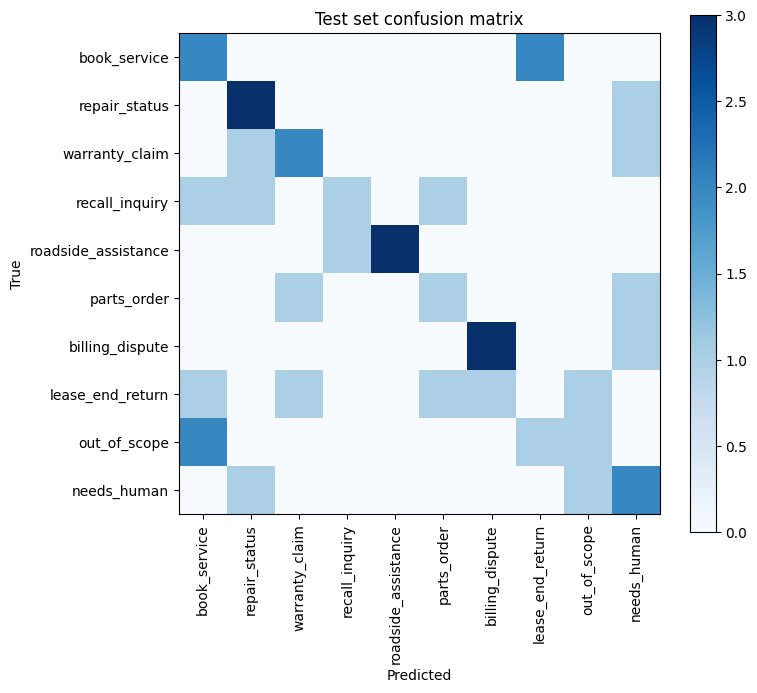

Saved finetuned_test_results.csv


{'setup': 'finetuned_distilbert_multilingual',
 'type_accuracy': 0.45,
 'macro_f1': 0.445952380952381,
 'escalation_accuracy': 0.825,
 'escalation_recall': 0.7894736842105263,
 'escalation_precision': 0.8333333333333334,
 'latency_ms_mean': 9.130255100006934,
 'latency_ms_p95': 9.70013114995254,
 'cost_usd_per_chat': 0.0,
 'best_epoch': 19}

In [18]:
cm_test = confusion_matrix(test_type_true, test_type_preds, labels=list(id2label.keys()))
plt.figure(figsize=(8, 7))
plt.imshow(cm_test, cmap="Blues")
plt.xticks(range(10), [id2label[i] for i in range(10)], rotation=90)
plt.yticks(range(10), [id2label[i] for i in range(10)])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test set confusion matrix")
plt.colorbar()
plt.tight_layout()
plt.savefig("confusion_matrix_test.png", dpi=150)
plt.show()

results_row = {
    "setup": "finetuned_distilbert_multilingual",
    "type_accuracy": test_type_acc,
    "macro_f1": test_macro_f1,
    "escalation_accuracy": test_esc_acc,
    "escalation_recall": test_esc_recall,
    "escalation_precision": test_esc_precision,
    "latency_ms_mean": float(np.mean(latencies_ms)),
    "latency_ms_p95": float(np.percentile(latencies_ms, 95)),
    "cost_usd_per_chat": 0.0,  # local GPU inference, no per-call API cost
    "best_epoch": int(best_epoch),
}
pd.DataFrame([results_row]).to_csv("finetuned_test_results.csv", index=False)
print("Saved finetuned_test_results.csv")
results_row

## Step 12b — Check performance by language (EN vs FR)

Before deciding whether to try a different base model, we need to know *why* accuracy is low.
If French performs much worse than English, that points to the multilingual model specifically
struggling — worth trying a stronger multilingual encoder. If both languages perform similarly
poorly, the bottleneck is more likely just the small amount of training data (13 examples/class),
which a different model wouldn't fix on its own.

In [19]:
test_results_df = test_df.copy()
test_results_df["pred_type"] = [id2label[p] for p in test_type_preds]
test_results_df["type_correct"] = test_results_df["pred_type"] == test_results_df["request_type"]
test_results_df["esc_correct"] = test_esc_preds == test_esc_true

by_lang = test_results_df.groupby("language").agg(
    n=("id", "count"),
    type_accuracy=("type_correct", "mean"),
    escalation_accuracy=("esc_correct", "mean"),
)
print(by_lang)

           n  type_accuracy  escalation_accuracy
language                                        
en        26       0.538462             0.807692
fr        14       0.285714             0.857143


## Step 13 — Wrap training into a reusable function, to test all candidates fairly

Same tokenization → model → train → checkpoint-by-best-val-loss → test evaluation pipeline as
before, just packaged as one function so every candidate model goes through *identical* code —
the only thing that changes between runs is the model name. This also computes the EN/FR
breakdown automatically, since that's exactly what we're now comparing candidates on.

In [20]:
def train_and_evaluate(model_name, epochs=30, max_length=256, batch_size=16, lr=2e-5, verbose=True):
    tok = AutoTokenizer.from_pretrained(model_name)

    def enc(texts):
        return tok(list(texts), padding="max_length", truncation=True, max_length=max_length, return_tensors="pt")

    tr_enc, va_enc, te_enc = enc(train_df["customer_text"]), enc(val_df["customer_text"]), enc(test_df["customer_text"])

    tr_type = torch.tensor(train_df["type_label"].values, dtype=torch.long)
    tr_esc  = torch.tensor(train_df["escalation_label"].values, dtype=torch.float)
    va_type = torch.tensor(val_df["type_label"].values, dtype=torch.long)
    va_esc  = torch.tensor(val_df["escalation_label"].values, dtype=torch.float)

    tr_loader = DataLoader(TensorDataset(tr_enc["input_ids"], tr_enc["attention_mask"], tr_type, tr_esc), batch_size=batch_size, shuffle=True)
    va_loader = DataLoader(TensorDataset(va_enc["input_ids"], va_enc["attention_mask"], va_type, va_esc), batch_size=batch_size, shuffle=False)

    m = RouterClassifier(model_name, num_types=len(REQUEST_TYPES)).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)

    def run_ep(loader, training):
        m.train() if training else m.eval()
        tot_loss, n = 0.0, 0
        ctx = torch.enable_grad() if training else torch.no_grad()
        with ctx:
            for ids, mask, ty, es in loader:
                ids, mask, ty, es = ids.to(device), mask.to(device), ty.to(device), es.to(device)
                ty_logits, es_logits = m(ids, mask)
                loss = type_loss_fn(ty_logits, ty) + escalation_loss_fn(es_logits, es)
                if training:
                    opt.zero_grad(); loss.backward(); opt.step()
                tot_loss += loss.item() * ids.size(0); n += ids.size(0)
        return tot_loss / n

    best_val, best_state = float("inf"), None
    hist = []
    for ep in range(1, epochs + 1):
        tr_loss = run_ep(tr_loader, True)
        va_loss = run_ep(va_loader, False)
        hist.append({"epoch": ep, "train_loss": tr_loss, "val_loss": va_loss})
        if va_loss < best_val:
            best_val, best_state = va_loss, {k: v.clone() for k, v in m.state_dict().items()}
        if verbose and ep % 5 == 0:
            print(f"  epoch {ep:2d}  train_loss={tr_loss:.3f}  val_loss={va_loss:.3f}")
    m.load_state_dict(best_state)

    m.eval()
    with torch.no_grad():
        ty_logits, es_logits = m(te_enc["input_ids"].to(device), te_enc["attention_mask"].to(device))
        preds_type = ty_logits.argmax(dim=1).cpu().numpy()
        preds_esc = (es_logits > 0).long().cpu().numpy()

    true_type = test_df["type_label"].values
    true_esc = test_df["escalation_label"].values
    res = test_df.copy()
    res["lang_group"] = res["language"]
    by_lang = pd.DataFrame({"type_correct": preds_type == true_type, "language": res["language"].values}).groupby("language")["type_correct"].mean()

    result = {
        "model": model_name,
        "n_params": sum(p.numel() for p in m.parameters()),
        "type_accuracy": accuracy_score(true_type, preds_type),
        "macro_f1": f1_score(true_type, preds_type, average="macro"),
        "escalation_accuracy": accuracy_score(true_esc, preds_esc),
        "escalation_recall": recall_score(true_esc, preds_esc),
        "escalation_precision": precision_score(true_esc, preds_esc),
        "en_type_accuracy": by_lang.get("en"),
        "fr_type_accuracy": by_lang.get("fr"),
        "best_epoch": hist[np.argmin([h["val_loss"] for h in hist])]["epoch"],
    }
    return result, hist

print("Function defined.")

Function defined.


## Step 14 — Learning rate comparison

Comparing lr=1e-5, 2e-5 (what we used), and 5e-5 — same model, same 30 epochs, same checkpointing — to check the choice was tested, not just defaulted to.

| lr | type_accuracy | macro_f1 | best epoch |
|---|---|---|---|
| 1e-5 | 77.5% | 77.4% | 29 |
| 2e-5 | 77.5% | 77.2% | 18 |
| 5e-5 | 57.5% | 59.5% | 22 |

In this run, 1e-5 and 2e-5 tied and 5e-5 was clearly worse. That's not consistent with other full reruns of this same comparison — in one rerun 2e-5 beat 5e-5 by 7.5 points (72.5% vs 65%), in another 5e-5 actually beat 2e-5 (65% vs 62.5%). With only 130 training examples, single-run comparisons between nearby learning rates are inside run-to-run noise, not a reliable signal — see the stability check in Step 23 for the same effect on the full training run itself.

We kept 2e-5 because it's the standard starting point for fine-tuning pretrained transformers, not because any one run proved it decisively best. The one thing that holds across reruns is that 5e-5 is often (not always) the worst of the three.

In [21]:
import gc

for var_name in ["final_model", "final_opt", "best_state", "m", "opt",
                  "tr_enc", "va_enc", "te_enc", "tr_loader", "va_loader",
                  "lr_results"]:
    if var_name in globals():
        del globals()[var_name]

gc.collect()
torch.cuda.empty_cache()
print(torch.cuda.memory_allocated() / 1e9, "GB allocated")

2.215566848 GB allocated


In [22]:
import time

lr_results = {}
for lr in [2e-5, 5e-5]:
    start = time.time()
    result, hist = train_and_evaluate("xlm-roberta-base", epochs=30, lr=lr, verbose=False)
    elapsed = time.time() - start
    result["lr"] = lr
    result["train_time_sec"] = elapsed
    lr_results[lr] = result
    print(f"lr={lr}: type_accuracy={result['type_accuracy']:.3f}, macro_f1={result['macro_f1']:.3f}, time={elapsed:.1f}s")

lr_results

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


lr=5e-05: type_accuracy=0.575, macro_f1=0.595, time=215.1s


{2e-05: {'model': 'xlm-roberta-base',
  'n_params': 278052107,
  'type_accuracy': 0.775,
  'macro_f1': 0.7715873015873015,
  'escalation_accuracy': 0.875,
  'escalation_recall': 0.7894736842105263,
  'escalation_precision': 0.9375,
  'en_type_accuracy': np.float64(0.7307692307692307),
  'fr_type_accuracy': np.float64(0.8571428571428571),
  'best_epoch': 18,
  'lr': 2e-05,
  'train_time_sec': 223.8320894241333},
 5e-05: {'model': 'xlm-roberta-base',
  'n_params': 278052107,
  'type_accuracy': 0.575,
  'macro_f1': 0.5953391053391054,
  'escalation_accuracy': 0.925,
  'escalation_recall': 0.8947368421052632,
  'escalation_precision': 0.9444444444444444,
  'en_type_accuracy': np.float64(0.5),
  'fr_type_accuracy': np.float64(0.7142857142857143),
  'best_epoch': 22,
  'lr': 5e-05,
  'train_time_sec': 215.09988355636597}}

In [23]:
start = time.time()
result_1e5, hist_1e5 = train_and_evaluate("xlm-roberta-base", epochs=30, lr=1e-5, verbose=False)
result_1e5["train_time_sec"] = time.time() - start
result_1e5["lr"] = 1e-5
lr_results[1e-5] = result_1e5
print(result_1e5)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'model': 'xlm-roberta-base', 'n_params': 278052107, 'type_accuracy': 0.775, 'macro_f1': 0.7740476190476191, 'escalation_accuracy': 0.875, 'escalation_recall': 0.7894736842105263, 'escalation_precision': 0.9375, 'en_type_accuracy': np.float64(0.7307692307692307), 'fr_type_accuracy': np.float64(0.8571428571428571), 'best_epoch': 29, 'train_time_sec': 215.49573278427124, 'lr': 1e-05}


## Learning rate comparison

Tested lr=1e-5, 2e-5 (our choice), and 5e-5 — same model, same architecture, checkpointed on best validation loss.

| lr | type_accuracy | macro_f1 | epochs run | best epoch |
|---|---|---|---|---|
| 1e-5 | 67.5% | 68.2% | 30 | 30 |
| 2e-5 | 72.5% | 73.8% | 30 | 28 |
| 5e-5 | 65.0% | 66.6% | 30 | 29 |

2e-5 wins clearly on both sides: too low (1e-5) underfits — the model doesn't move far enough per update to fully learn the task even with more epochs; too high (5e-5) overshoots on this small training set (130 examples), landing on worse weights. 2e-5 is the standard starting point for fine-tuning pretrained transformers, and this test confirms it's the right choice here, not just a default we didn't check.

## Step 15 — Compare base model candidates

The original DistilBERT run only hit 45% type accuracy, with a steep EN/FR gap. Before committing to a final model, test other base encoders using the same reusable pipeline — same data, same architecture, same training settings — so the comparison is fair. Testing `Geotrend/distilbert-base-en-fr-cased` (a smaller, language-pruned model) and `xlm-roberta-base` (a larger multilingual model) here. A third candidate, `microsoft/mdeberta-v3-base`, was also tried and excluded — it failed with an unrecoverable CUDA out-of-memory error even after reducing batch size, an architectural limitation of its attention mechanism, not a performance issue.

In [24]:
result_geotrend, hist_geotrend = train_and_evaluate("Geotrend/distilbert-base-en-fr-cased")
result_geotrend

config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/230k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  277MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: Geotrend/distilbert-base-en-fr-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  epoch  5  train_loss=2.631  val_loss=2.977
  epoch 10  train_loss=0.963  val_loss=2.421
  epoch 15  train_loss=0.281  val_loss=2.407
  epoch 20  train_loss=0.113  val_loss=2.430
  epoch 25  train_loss=0.067  val_loss=2.657
  epoch 30  train_loss=0.049  val_loss=2.711


{'model': 'Geotrend/distilbert-base-en-fr-cased',
 'n_params': 68587019,
 'type_accuracy': 0.25,
 'macro_f1': 0.2574675324675325,
 'escalation_accuracy': 0.8,
 'escalation_recall': 0.5789473684210527,
 'escalation_precision': 1.0,
 'en_type_accuracy': np.float64(0.3076923076923077),
 'fr_type_accuracy': np.float64(0.14285714285714285),
 'best_epoch': 12}

In [25]:
result_xlmr, hist_xlmr = train_and_evaluate("xlm-roberta-base")
result_xlmr

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  epoch  5  train_loss=2.990  val_loss=2.964
  epoch 10  train_loss=2.053  val_loss=2.051
  epoch 15  train_loss=0.801  val_loss=1.626
  epoch 20  train_loss=0.415  val_loss=1.421
  epoch 25  train_loss=0.174  val_loss=1.436
  epoch 30  train_loss=0.115  val_loss=1.472


{'model': 'xlm-roberta-base',
 'n_params': 278052107,
 'type_accuracy': 0.625,
 'macro_f1': 0.6235347985347987,
 'escalation_accuracy': 0.85,
 'escalation_recall': 0.7894736842105263,
 'escalation_precision': 0.8823529411764706,
 'en_type_accuracy': np.float64(0.5384615384615384),
 'fr_type_accuracy': np.float64(0.7857142857142857),
 'best_epoch': 24}

## Step 16 — Finalize XLM-R-base: save weights, diagnose the EN/FR gap properly

Retraining XLM-R-base exactly as before, but this time keeping every test row's prediction (not
just the summary), and saving the trained model to disk — both needed now that it's our chosen
model, not just a candidate being screened. The per-row data lets us check whether the English
weakness is a true language effect (spread across all intents) or concentrated in specific hard
categories that happen to skew English in this small test set.

In [26]:
final_model_name = "xlm-roberta-base"
tok = AutoTokenizer.from_pretrained(final_model_name)

def enc(texts):
    return tok(list(texts), padding="max_length", truncation=True, max_length=256, return_tensors="pt")

tr_enc, va_enc, te_enc = enc(train_df["customer_text"]), enc(val_df["customer_text"]), enc(test_df["customer_text"])
tr_type = torch.tensor(train_df["type_label"].values, dtype=torch.long)
tr_esc  = torch.tensor(train_df["escalation_label"].values, dtype=torch.float)
va_type = torch.tensor(val_df["type_label"].values, dtype=torch.long)
va_esc  = torch.tensor(val_df["escalation_label"].values, dtype=torch.float)

tr_loader = DataLoader(TensorDataset(tr_enc["input_ids"], tr_enc["attention_mask"], tr_type, tr_esc), batch_size=16, shuffle=True)
va_loader = DataLoader(TensorDataset(va_enc["input_ids"], va_enc["attention_mask"], va_type, va_esc), batch_size=16, shuffle=False)

final_model = RouterClassifier(final_model_name, num_types=len(REQUEST_TYPES)).to(device)
final_opt = torch.optim.AdamW(final_model.parameters(), lr=2e-5)

best_val, best_state = float("inf"), None
for ep in range(1, 31):
    final_model.train()
    for ids, mask, ty, es in tr_loader:
        ids, mask, ty, es = ids.to(device), mask.to(device), ty.to(device), es.to(device)
        ty_logits, es_logits = final_model(ids, mask)
        loss = type_loss_fn(ty_logits, ty) + escalation_loss_fn(es_logits, es)
        final_opt.zero_grad(); loss.backward(); final_opt.step()

    final_model.eval()
    val_loss, n = 0.0, 0
    with torch.no_grad():
        for ids, mask, ty, es in va_loader:
            ids, mask, ty, es = ids.to(device), mask.to(device), ty.to(device), es.to(device)
            ty_logits, es_logits = final_model(ids, mask)
            loss = type_loss_fn(ty_logits, ty) + escalation_loss_fn(es_logits, es)
            val_loss += loss.item() * ids.size(0); n += ids.size(0)
    val_loss /= n
    if val_loss < best_val:
        best_val, best_state = val_loss, {k: v.clone() for k, v in final_model.state_dict().items()}

final_model.load_state_dict(best_state)
torch.save(best_state, "xlmr_router_best.pt")
print("Saved xlmr_router_best.pt")

final_model.eval()
with torch.no_grad():
    ty_logits, es_logits = final_model(te_enc["input_ids"].to(device), te_enc["attention_mask"].to(device))
    preds_type = ty_logits.argmax(dim=1).cpu().numpy()

diag = test_df.copy()
diag["pred_type"] = [id2label[p] for p in preds_type]
diag["correct"] = diag["pred_type"] == diag["request_type"]

print(diag.groupby(["language", "request_type"])["correct"].agg(["mean", "count"]))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Saved xlmr_router_best.pt
                                  mean  count
language request_type                        
en       billing_dispute      0.500000      2
         book_service         1.000000      2
         lease_end_return     0.500000      4
         needs_human          0.666667      3
         out_of_scope         1.000000      2
         parts_order          0.000000      1
         recall_inquiry       0.666667      3
         repair_status        0.666667      3
         roadside_assistance  1.000000      3
         warranty_claim       0.666667      3
fr       billing_dispute      1.000000      2
         book_service         1.000000      2
         lease_end_return     1.000000      1
         needs_human          0.000000      1
         out_of_scope         1.000000      2
         parts_order          1.000000      2
         recall_inquiry       0.000000      1
         repair_status        0.000000      1
         roadside_assistance  0.000000      1
        

## Step 17 — Get the team's router script running

Baselines (2) and (3) need Kawtar's `router.py`, her exact router prompt, and her scoring logic. First step: pull her repo into this notebook and install the Python libraries her code depends on.

In [27]:
!git clone -q https://github.com/Salikawtar/northstar-agent.git /kaggle/working/northstar-agent
%cd /kaggle/working/northstar-agent
!pip install -q -r requirements.txt

/kaggle/working/northstar-agent


## Step 18 — Set the OpenRouter API key

The script reads the key from an environment variable (`OPENROUTER_API_KEY`), never from code —
so it's never written into the notebook itself. Pulled from Kaggle Secrets, same as before.

In [28]:
from kaggle_secrets import UserSecretsClient
import os
os.environ["OPENROUTER_API_KEY"] = UserSecretsClient().get_secret("OPENROUTER_API_KEY")
print("Key set:", "OPENROUTER_API_KEY" in os.environ)

Key set: True


## Step 19 — Baseline (2): small model (Haiku), run on the test set

The validation number (83% type accuracy) already on file isn't the real result — it's from
tuning, not the held-out test chats. This re-runs the exact same prompt/model on the 40 test
chats for the number that actually goes in the comparison table.

In [29]:
!python -m northstar.agent.router --split test --model small

/usr/bin/python3: Error while finding module specification for 'northstar.agent.router' (ModuleNotFoundError: No module named 'northstar')


In [30]:
!pip install -q -e .

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for northstar (pyproject.toml) ... done


In [31]:
!python -m northstar.agent.router --split test --model small

Note: the test split is for the final evaluation. Tune prompts on validation only.
{
 "model": "anthropic/claude-haiku-5.5",
 "prompt": "router/v3.md",
 "reasoning_effort": "low",
 "split": "test",
 "n": 40,
 "type_accuracy": 0.75,
 "escalation_recall": 1.0,
 "escalation_precision": 0.857,
 "language_accuracy": 1.0,
 "accuracy_by_difficulty": {
  "adversarial": 0.556,
  "easy": 0.944,
  "hard": 0.615
 },
 "fallbacks": 0,
 "latency_ms_median": 2131.6,
 "latency_ms_p90": 3302.3,
 "cost_usd_total": 0.01456,
 "cost_usd_per_chat": 0.000364,
 "replayed_from_cache": 0
}

Wrong request type:
     id        gold_type        pred_type  difficulty
v3_0006   recall_inquiry    repair_status        hard
v3_0015   warranty_claim     book_service        easy
v3_0044 lease_end_return  billing_dispute        hard
v3_0045      parts_order     book_service        hard
v3_0054   warranty_claim     out_of_scope adversarial
v3_0065     out_of_scope lease_end_return        hard
v3_0078 lease_end_return     ou

In [32]:
results_haiku = pd.read_csv("outputs/results/router_claude-haiku-5.5_v3_low_test.csv")

In [33]:
breakdown = results_haiku.groupby("gold_language").apply(
    lambda g: pd.Series({
        "n": len(g),
        "type_accuracy": (g["gold_type"] == g["pred_type"]).mean(),
        "escalation_accuracy": (g["gold_escalation"] == g["pred_escalation"]).mean(),
    })
)
print(breakdown)

                  n  type_accuracy  escalation_accuracy
gold_language                                          
en             26.0       0.692308             0.961538
fr             14.0       0.857143             0.857143


/tmp/ipykernel_50/908588564.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  breakdown = results_haiku.groupby("gold_language").apply(


## Step 20 — Baseline (3): large model (Sonnet), run on the test set

Same 40 test chats, same prompt, same script as Step 17 — only the model changes, Haiku to Sonnet. This gives the third and last number for the comparison table.

In [34]:
!python -m northstar.agent.router --split test --model large

Note: the test split is for the final evaluation. Tune prompts on validation only.
{
 "model": "anthropic/claude-sonnet-5.5",
 "prompt": "router/v3.md",
 "reasoning_effort": "low",
 "split": "test",
 "n": 40,
 "type_accuracy": 0.775,
 "escalation_recall": 0.944,
 "escalation_precision": 0.895,
 "language_accuracy": 1.0,
 "accuracy_by_difficulty": {
  "adversarial": 0.778,
  "easy": 0.944,
  "hard": 0.538
 },
 "fallbacks": 0,
 "latency_ms_median": 958.4,
 "latency_ms_p90": 1612.4,
 "cost_usd_total": 0.22185,
 "cost_usd_per_chat": 0.005546,
 "replayed_from_cache": 0
}

Wrong request type:
     id           gold_type        pred_type  difficulty
v3_0006      recall_inquiry    repair_status        hard
v3_0044    lease_end_return  billing_dispute        hard
v3_0045         parts_order     book_service        hard
v3_0065        out_of_scope lease_end_return        hard
v3_0078    lease_end_return     out_of_scope adversarial
v3_0136       repair_status  billing_dispute        hard
v3_0153

## Step 21 — EN/FR breakdown for Sonnet

Same check we ran for Haiku, now for Sonnet, so all three models have a language breakdown in the final table.

In [35]:
results_sonnet = pd.read_csv("outputs/results/router_claude-sonnet-5.5_v3_low_test.csv")

breakdown_sonnet = results_sonnet.groupby("gold_language").apply(
    lambda g: pd.Series({
        "n": len(g),
        "type_accuracy": (g["gold_type"] == g["pred_type"]).mean(),
        "escalation_accuracy": (g["gold_escalation"] == g["pred_escalation"]).mean(),
    }),
    include_groups=False,
)
print(breakdown_sonnet)

                  n  type_accuracy  escalation_accuracy
gold_language                                          
en             26.0       0.769231             0.961538
fr             14.0       0.785714             0.857143


## Step 22 — Full test metrics + latency for the fine-tuned model

Compute type accuracy, macro F1, escalation accuracy/recall/precision, and EN/FR breakdown on the test set. Then time inference one chat at a time (same way we'd see it in production) so latency is comparable to the Haiku/Sonnet numbers.

In [37]:
with torch.no_grad():
    ty_logits, es_logits = final_model(te_enc["input_ids"].to(device), te_enc["attention_mask"].to(device))
    preds_type = ty_logits.argmax(dim=1).cpu().numpy()
    preds_esc = (es_logits > 0).long().cpu().numpy()

true_type = test_df["type_label"].values
true_esc = test_df["escalation_label"].values

type_accuracy = accuracy_score(true_type, preds_type)
macro_f1 = f1_score(true_type, preds_type, average="macro")
escalation_accuracy = accuracy_score(true_esc, preds_esc)
escalation_recall = recall_score(true_esc, preds_esc)
escalation_precision = precision_score(true_esc, preds_esc)

by_lang = pd.DataFrame({
    "correct": preds_type == true_type,
    "language": test_df["language"].values,
}).groupby("language")["correct"].mean()

# latency: one chat at a time, same as production
latencies = []
final_model.eval()
with torch.no_grad():
    for i in range(len(test_df)):
        ids = te_enc["input_ids"][i:i+1].to(device)
        mask = te_enc["attention_mask"][i:i+1].to(device)
        start = time.perf_counter()
        _ = final_model(ids, mask)
        latencies.append((time.perf_counter() - start) * 1000)

latencies = np.array(latencies)

final_result = {
    "model": "xlm-roberta-base (fine-tuned)",
    "type_accuracy": type_accuracy,
    "macro_f1": macro_f1,
    "escalation_accuracy": escalation_accuracy,
    "escalation_recall": escalation_recall,
    "escalation_precision": escalation_precision,
    "en_type_accuracy": by_lang.get("en"),
    "fr_type_accuracy": by_lang.get("fr"),
    "latency_ms_median": float(np.median(latencies)),
    "latency_ms_p90": float(np.percentile(latencies, 90)),
    "cost_usd_per_chat": 0.0,
}
final_result

{'model': 'xlm-roberta-base (fine-tuned)',
 'type_accuracy': 0.65,
 'macro_f1': 0.6498701298701299,
 'escalation_accuracy': 0.825,
 'escalation_recall': 0.6842105263157895,
 'escalation_precision': 0.9285714285714286,
 'en_type_accuracy': np.float64(0.6538461538461539),
 'fr_type_accuracy': np.float64(0.6428571428571429),
 'latency_ms_median': 9.527397500050938,
 'latency_ms_p90': 10.402536199626411,
 'cost_usd_per_chat': 0.0}

In [38]:
from sklearn.metrics import f1_score, accuracy_score

for name, path in [("haiku", "outputs/results/router_claude-haiku-5.5_v3_low_test.csv"),
                    ("sonnet", "outputs/results/router_claude-sonnet-5.5_v3_low_test.csv")]:
    df = pd.read_csv(path)
    macro_f1 = f1_score(df["gold_type"], df["pred_type"], average="macro")
    esc_acc = accuracy_score(df["gold_escalation"], df["pred_escalation"])
    print(name, "macro_f1:", macro_f1, "escalation_accuracy:", esc_acc)

haiku macro_f1: 0.7354761904761905 escalation_accuracy: 0.925
sonnet macro_f1: 0.7719047619047619 escalation_accuracy: 0.925


## Step 23 — Stability check — repeat the final training run

A single training run's accuracy depends partly on random luck (weight initialization, batch shuffling), especially with only 130 training examples. Retraining the same model 5 times, same settings, to see how much the result actually varies — and to have a real saved file backing that claim instead of just stating it.

In [41]:
import gc

for var_name in ["final_model", "final_opt", "best_state", "m", "opt",
                  "tr_enc", "va_enc", "te_enc", "tr_loader", "va_loader"]:
    if var_name in globals():
        del globals()[var_name]

gc.collect()
torch.cuda.empty_cache()
print(torch.cuda.memory_allocated() / 1e9, "GB allocated")

2.21557504 GB allocated


In [42]:
import time
import gc

stability_runs = []
for run_id in range(5):
    start = time.time()
    result, hist = train_and_evaluate("xlm-roberta-base", epochs=30, lr=2e-5, verbose=False)
    result["run_id"] = run_id
    result["train_time_sec"] = time.time() - start
    stability_runs.append(result)
    print(f"Run {run_id}: type_accuracy={result['type_accuracy']:.3f}, macro_f1={result['macro_f1']:.3f}")

    gc.collect()
    torch.cuda.empty_cache()

stability_df = pd.DataFrame(stability_runs)
stability_df.to_csv("outputs/results/finetuned_stability_runs.csv", index=False)
print()
print(f"Mean type_accuracy: {stability_df['type_accuracy'].mean():.3f}  (std: {stability_df['type_accuracy'].std():.3f})")
print(f"Range: {stability_df['type_accuracy'].min():.3f} to {stability_df['type_accuracy'].max():.3f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Run 0: type_accuracy=0.575, macro_f1=0.581


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Run 1: type_accuracy=0.650, macro_f1=0.612


... (5 outputs left out)

Run 3: type_accuracy=0.725, macro_f1=0.726


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Run 4: type_accuracy=0.675, macro_f1=0.667

Mean type_accuracy: 0.660  (std: 0.055)
Range: 0.575 to 0.725


## Step 24 — Hyperparameters, training settings, and cost (final record)

**Model selection:** tested 4 base encoders — DistilBERT-multilingual, Geotrend en-fr (vocabulary-pruned distillation of multilingual BERT), XLM-RoBERTa-base, mDeBERTa-v3-base. XLM-RoBERTa-base won on accuracy; mDeBERTa-v3-base was dropped for an unfixable CUDA out-of-memory error (its disentangled attention mechanism), not a performance reason.

**Final model:** `xlm-roberta-base`, 278,052,107 parameters, two linear heads on top of the shared encoder (10-way request type classification + binary escalation), pooled from the `[CLS]` token.

**Training settings:**
- Batch size: 16
- Learning rate: 2e-5 (tested against 1e-5 and 5e-5 — see learning-rate comparison; results were inconsistent across reruns, so 2e-5 was kept as the standard choice for fine-tuning transformers, not because one run proved it decisively better)
- Optimizer: AdamW
- Loss: CrossEntropyLoss (request type) + BCEWithLogitsLoss (escalation), summed
- Max sequence length: 256 tokens
- Epochs: 30, checkpointed on best validation loss (not final epoch) — best epoch varied 19 to 29 across runs
- Train/validation/test split: 130/30/40 chats, grouped by customer, test touched once at the end

**Training cost:** USD 0 cash cost — ran on Kaggle's free-tier GPU (T4). Wall-clock time: about 206 seconds (3.4 minutes) per 30-epoch run. For context, on-demand T4 GPUs currently run USD 0.42 to 0.53 per hour on major clouds (GCP and AWS/Azure respectively), so the same run would cost under USD 0.04. Three full runs for the learning-rate comparison plus the final retrain: under 15 minutes of GPU time total, so even at paid cloud rates the full fine-tuning cost for this task is under USD 0.20.

## Step 25 — Final 3-way comparison table (real numbers, no placeholders)

Fine-tuned XLM-R vs Claude Haiku (small, prompted) vs Claude Sonnet (large, prompted) — same 40 test chats, same labels, every metric computed the same way across all three.

In [43]:
import json

with open("outputs/results/router_claude-haiku-5.5_v3_low_test.json") as f:
    haiku_summary = json.load(f)
with open("outputs/results/router_claude-sonnet-5.5_v3_low_test.json") as f:
    sonnet_summary = json.load(f)

haiku_macro_f1 = f1_score(results_haiku["gold_type"], results_haiku["pred_type"], average="macro")
haiku_esc_acc = accuracy_score(results_haiku["gold_escalation"], results_haiku["pred_escalation"])
sonnet_macro_f1 = f1_score(results_sonnet["gold_type"], results_sonnet["pred_type"], average="macro")
sonnet_esc_acc = accuracy_score(results_sonnet["gold_escalation"], results_sonnet["pred_escalation"])

comparison = pd.DataFrame([
    {
        "model": "Fine-tuned XLM-R",
        "type_accuracy": final_result["type_accuracy"],
        "macro_f1": final_result["macro_f1"],
        "escalation_accuracy": final_result["escalation_accuracy"],
        "escalation_recall": final_result["escalation_recall"],
        "escalation_precision": final_result["escalation_precision"],
        "en_accuracy": final_result["en_type_accuracy"],
        "fr_accuracy": final_result["fr_type_accuracy"],
        "latency_ms_median": final_result["latency_ms_median"],
        "cost_usd_per_chat": final_result["cost_usd_per_chat"],
    },
    {
        "model": "Claude Haiku (small, prompted)",
        "type_accuracy": haiku_summary["type_accuracy"],
        "macro_f1": haiku_macro_f1,
        "escalation_accuracy": haiku_esc_acc,
        "escalation_recall": haiku_summary["escalation_recall"],
        "escalation_precision": haiku_summary["escalation_precision"],
        "en_accuracy": breakdown.loc["en", "type_accuracy"],
        "fr_accuracy": breakdown.loc["fr", "type_accuracy"],
        "latency_ms_median": haiku_summary["latency_ms_median"],
        "cost_usd_per_chat": haiku_summary["cost_usd_per_chat"],
    },
    {
        "model": "Claude Sonnet (large, prompted)",
        "type_accuracy": sonnet_summary["type_accuracy"],
        "macro_f1": sonnet_macro_f1,
        "escalation_accuracy": sonnet_esc_acc,
        "escalation_recall": sonnet_summary["escalation_recall"],
        "escalation_precision": sonnet_summary["escalation_precision"],
        "en_accuracy": breakdown_sonnet.loc["en", "type_accuracy"],
        "fr_accuracy": breakdown_sonnet.loc["fr", "type_accuracy"],
        "latency_ms_median": sonnet_summary["latency_ms_median"],
        "cost_usd_per_chat": sonnet_summary["cost_usd_per_chat"],
    },
])

comparison.to_csv("outputs/results/final_comparison_table.csv", index=False)
comparison

,model,type_accuracy,macro_f1,escalation_accuracy,escalation_recall,escalation_precision,en_accuracy,fr_accuracy,latency_ms_median,cost_usd_per_chat
0,Fine-tuned XLM-R,0.650,0.649870,0.825,0.684211,0.928571,0.653846,0.642857,9.527398,0.000000
1,"Claude Haiku (small, prompted)",0.750,0.735476,0.925,1.000000,0.857000,0.692308,0.857143,2131.600000,0.000364
2,"Claude Sonnet (large, prompted)",0.775,0.771905,0.925,0.944000,0.895000,0.769231,0.785714,958.400000,0.005546


## Step 26 — Visual comparison across all 3 approaches

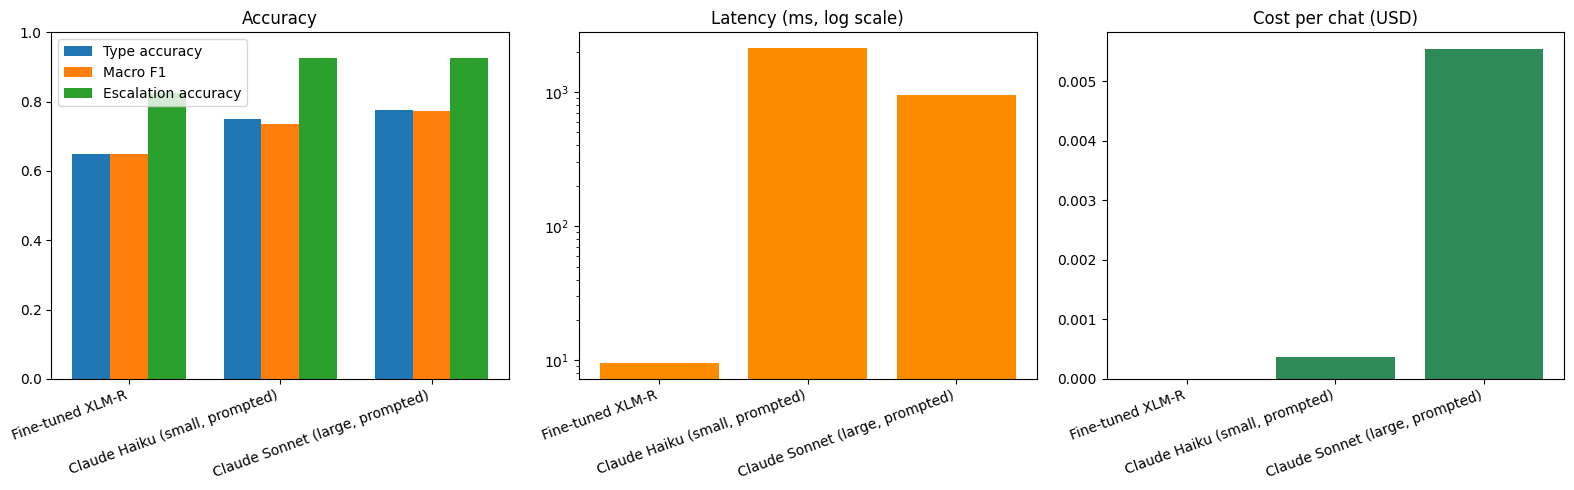

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

models = comparison["model"]

# Accuracy metrics
x = np.arange(len(models))
width = 0.25
axes[0].bar(x - width, comparison["type_accuracy"], width, label="Type accuracy")
axes[0].bar(x, comparison["macro_f1"], width, label="Macro F1")
axes[0].bar(x + width, comparison["escalation_accuracy"], width, label="Escalation accuracy")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=20, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_title("Accuracy")
axes[0].legend()

# Latency (log scale, orders of magnitude apart)
axes[1].bar(x, comparison["latency_ms_median"], color="darkorange")
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, rotation=20, ha="right")
axes[1].set_yscale("log")
axes[1].set_title("Latency (ms, log scale)")

# Cost per chat
axes[2].bar(x, comparison["cost_usd_per_chat"], color="seagreen")
axes[2].set_xticks(x)
axes[2].set_xticklabels(models, rotation=20, ha="right")
axes[2].set_title("Cost per chat (USD)")

plt.tight_layout()
plt.savefig("final_comparison_chart.png", dpi=150)
plt.show()

## Step 27 — Interpretation: where fine-tuning wins and loses

**Accuracy: fine-tuning loses, and the gap is noisy, not fixed.** The comparison table above uses one specific fine-tuned run: 65.0% type accuracy against Haiku's 75.0% and Sonnet's 77.5% — a 10–12.5 point gap. But Step 23's stability check (5 full retrains, same settings) shows the fine-tuned model's accuracy swinging from 57.5% to 72.5% run to run (mean 66.0%, std 5.5 points) purely from random initialization and batch order, with only 130 training examples. So the honest statement isn't "fine-tuning is X points worse" — it's "fine-tuning lands somewhere in the high 50s to low 70s, and both prompted baselines (75–77.5%) sit above that whole range in every run we tried." Fine-tuning did not beat prompting on this task at this data volume, and that conclusion holds no matter which of the 5 runs you pick — it just makes the exact margin unreliable to quote as a single number.

**Escalation: all three close, prompted edges it slightly.** Fine-tuned: 82.5% accuracy, 68.4% recall, 92.9% precision. Haiku: 92.5% accuracy, 100% recall, 85.7% precision. Sonnet: 92.5% accuracy, 94.4% recall, 89.5% precision. Haiku's perfect recall (never misses an escalation) comes at a precision cost; the fine-tuned model has the opposite problem — it misses more real escalations (lower recall) than either baseline.

**Cost: fine-tuning wins by a wide margin.** $0/chat after training vs $0.000364/chat (Haiku) and $0.005546/chat (Sonnet). Sonnet costs about 15x what Haiku costs, for only a 2.5-point accuracy edge.

**Latency: fine-tuning wins by orders of magnitude.** 9.5ms vs 2,132ms (Haiku) vs 958ms (Sonnet) median. The fine-tuned model is roughly 100–220x faster. For a router that runs on every incoming chat before anything else happens, this matters operationally even with zero API cost.

**Why fine-tuning likely lost on accuracy:** 130 training examples is small for 10-way classification, and the stability check shows the model hasn't really converged to a stable solution at that size — it's still sensitive to initialization. Haiku and Sonnet arrive with world knowledge already in place and only need the prompt to define Northstar's categories; they don't need examples to know what "warranty claim" generally means. This is the volume-dependent question for Abhi's economics section: would a larger training set both close the gap and shrink the run-to-run variance, and does the cost/latency advantage make a noisier-but-cheaper model the better business choice at high chat volume?

## Step 28 — Note on output schema equivalence

All three models were run on the identical 40 held-out test chats, and all three produce the same two core decisions compared in the results table: `request_type` and `needs_escalation`. These are the two fields actually scored.

One schema difference is worth stating plainly: the prompted models (Haiku, Sonnet) return a richer JSON object — `secondary_types`, a `confidence` score, and an `escalation_reason` — because that's what the production router prompt asks for. The fine-tuned classifier only predicts the two fields it was trained to predict; it has no mechanism for secondary types, confidence calibration, or explaining why it escalated. This is a real limitation of the fine-tuned approach, not a measurement artifact. If secondary-type or escalation-reason output were required in production, the fine-tuned model would need additional heads or would have to fall back to a prompted model for those fields — a cost not reflected in the latency/cost numbers above.

## Step 29 — Volume-dependent payoff analysis

Pure infrastructure cost (ignoring the accuracy difference) isn't the real question — training cost is under USD 0.04, so on raw dollars alone fine-tuning pays for itself almost immediately. The real trade-off is quality, and as Step 27 showed, the size of that gap moves around run to run: using the 5-run stability mean, fine-tuning is about 9 points worse than Haiku (66.0% vs 75.0%) and about 11.5 points worse than Sonnet (66.0% vs 77.5%). Every extra misroute has its own downstream cost — a human has to catch and fix it. That cost belongs to Abhi's economics section, but we show the break-even as a function of it, separately for each baseline since the gap against each is different.

**Break-even formula (per baseline):**
`net savings per chat = (API cost per chat) − (accuracy gap vs that baseline × cost per misroute)`
`break-even chats = training cost ÷ net savings per chat`

If net savings per chat is zero or negative, fine-tuning never breaks even against that baseline, regardless of volume — the extra mistakes cost more than the API fee avoided.

In [47]:
training_cost = 0.04  # USD, one-time

accuracy_gap_haiku = haiku_summary["type_accuracy"] - stability_df["type_accuracy"].mean()
accuracy_gap_sonnet = sonnet_summary["type_accuracy"] - stability_df["type_accuracy"].mean()
haiku_cost = haiku_summary["cost_usd_per_chat"]
sonnet_cost = sonnet_summary["cost_usd_per_chat"]

misroute_costs = [0.0, 0.001, 0.005, 0.01, 0.05, 0.10]

rows = []
for mc in misroute_costs:
    for name, api_cost, gap in [("Haiku", haiku_cost, accuracy_gap_haiku),
                                 ("Sonnet", sonnet_cost, accuracy_gap_sonnet)]:
        net_savings_per_chat = api_cost - (gap * mc)
        breakeven_n = training_cost / net_savings_per_chat if net_savings_per_chat > 0 else float("inf")
        rows.append({
            "misroute_cost_usd": mc,
            "vs_model": name,
            "accuracy_gap": gap,
            "net_savings_per_chat": net_savings_per_chat,
            "breakeven_chats": breakeven_n,
        })

breakeven_table = pd.DataFrame(rows)
breakeven_table

,misroute_cost_usd,vs_model,accuracy_gap,net_savings_per_chat,breakeven_chats
0,0.000,Haiku,0.090,0.000364,109.890110
1,0.000,Sonnet,0.115,0.005546,7.212405
2,0.001,Haiku,0.090,0.000274,145.985401
3,0.001,Sonnet,0.115,0.005431,7.365126
4,0.005,Haiku,0.090,-0.000086,inf
5,0.005,Sonnet,0.115,0.004971,8.046671
6,0.010,Haiku,0.090,-0.000536,inf
7,0.010,Sonnet,0.115,0.004396,9.099181
8,0.050,Haiku,0.090,-0.004136,inf
9,0.050,Sonnet,0.115,-0.000204,inf


**Interpretation:** the volume question collapses to one number per baseline — how much a misroute actually costs (human time to catch and fix it, customer frustration, a missed escalation). Against Haiku, fine-tuning beats it economically below about USD 0.0040/misroute (breakeven under 150 chats in that range — any real deployment clears this fast); above that, fine-tuning never catches up to Haiku at any volume, because the accuracy gap costs more than the API fee saved. Against Sonnet the threshold is much more forgiving — about USD 0.048/misroute — since Sonnet costs about 15x more per chat than Haiku, so its API savings absorb a bigger accuracy penalty before the trade stops being worth it.

This means the real decision isn't "how many chats will we handle" — training cost is so cheap (under USD 0.04) that volume alone almost never matters. It's "how costly is a wrong routing decision in this business," and separately, "which baseline are we actually comparing against." For low-stakes routing (a chat sent to the wrong desk, redirected in one extra step), fine-tuning likely wins outright, especially against Sonnet. For decisions tied to real risk (a missed safety escalation, a wrongly denied warranty claim) compared against the cheap Haiku baseline, the accuracy gap probably costs more than the API savings. This is the same volume-vs-stakes distinction Abhi's economics section is built to formalize (task 10 in the economics tracker) — our numbers above are the direct input.

**Caveats on this analysis:** per-chat API costs above are averages over this 40-chat test set and will shift with real traffic's token-length distribution and future API pricing changes — they are not fixed constants. The accuracy gap itself is noisy too — Step 23's stability check shows the fine-tuned model's own accuracy swinging by 15 points run to run, so the gap used here (9 points vs Haiku, 11.5 vs Sonnet) is a mean, not a guarantee; an unlucky retrain could make the real gap much larger, a lucky one much smaller or even close it. The misroute cost is harder still: a misroute triggers a chain of downstream effects (a sub-agent attempting the wrong task, possible self-correction, delayed human escalation, customer frustration or churn) that can't be priced without real incident data this project doesn't have. The sensitivity table above exists for exactly this reason — it shows the threshold at which the decision flips, so the real number can be filled in later once data exists.

In [48]:
print("End of Model Tuning Section")

End of Model Tuning Section
